# [Project title] ??

**Team members:** Nina Breen, Marin Marcillac, Claire McGinn, Roney Nguyen
**Repository:** https://github.com/9-uh/DS3001_Project_Group4

## Setup

Use relative paths and keep the notebook runnable from beginning to end.

In [1]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
assert DATA_DIR.is_dir(), "The data directory is missing."

## Load data

In [12]:
listing_df = pd.read_csv('data/listing_data.csv')
calendar_df = pd.read_csv('data/past_calendar_rates.csv')


## Prepare data

In [15]:
calendar_df["date"] = pd.to_datetime(calendar_df["date"], errors="coerce")

# Track missingness for key fields
for col in ["bedrooms", "guests"]:
    if col in listing_df.columns:
        listing_df[f"{col}_was_missing"] = listing_df[col].isna().astype(int)

# if the bedroom was not listed but the description or listing name contains "studio", set bedroom to 1
studio_mask = (
    listing_df["bedrooms"].isna()
    & (
        listing_df["listing_name"].fillna("").str.contains("studio", case=False, regex=False)
        | listing_df["description"].fillna("").str.contains("studio", case=False, regex=False)
    )
)
listing_df.loc[studio_mask, "bedrooms"] = 1.0
# filling other bedrooms with the median
bedroom_median_int = int(round(listing_df["bedrooms"].median()))
listing_df["bedrooms"] = listing_df["bedrooms"].fillna(bedroom_median_int).astype(int)

bool_cols = [
    "superhost", "registration", "professional_management",
    "instant_book", "guest_favorite", "exact_location", "single_fee_structure"
]
for col in bool_cols:
    if col in listing_df.columns:
        mapped = listing_df[col].map({True: 1, False: 0, "True": 1, "False": 0})
        listing_df[col] = mapped.fillna(0).astype(int)

# 3. Median-impute numeric listing features
num_cols = [
    "guests", "beds", "baths", "cleaning_fee", "min_nights",
    "num_reviews", "rating_overall", "rating_accuracy", "rating_checkin",
    "rating_cleanliness", "rating_communication", "rating_location", "rating_value",
    "ttm_avg_rate", "ttm_occupancy", "l90d_avg_rate", "l90d_occupancy"
]
for col in num_cols:
    if col in listing_df.columns:
        listing_df[col] = pd.to_numeric(listing_df[col], errors="coerce")
        listing_df[col] = listing_df[col].fillna(listing_df[col].median())

# 4. Drop IDs, text/URLs, sparse cols, and extra ttm/l90d duplicates
drop_listing = [
    "host_id", "listing_name", "description", "cover_photo_url", "photo_urls",
    "host_name", "cohost_ids", "cohost_names", "amenities", "checkin_time", "checkout_time",
    "extra_guest_fee", "currency", "ttm_total_days", "l90d_total_days",
    "ttm_revenue", "ttm_revenue_native", "ttm_avg_rate_native", "ttm_revpar",
    "ttm_revpar_native", "ttm_adjusted_revpar", "ttm_adjusted_revpar_native",
    "ttm_avg_min_nights", "ttm_avg_length_of_stay", "ttm_reserved_days",
    "ttm_blocked_days", "ttm_available_days", "ttm_adjusted_occupancy",
    "l90d_revenue", "l90d_revenue_native", "l90d_avg_rate_native", "l90d_revpar",
    "l90d_revpar_native", "l90d_adjusted_revpar", "l90d_adjusted_revpar_native",
    "l90d_avg_min_nights", "l90d_avg_length_of_stay", "l90d_reserved_days",
    "l90d_blocked_days", "l90d_available_days", "l90d_adjusted_occupancy"
]
listing_clean = listing_df.drop(columns=[c for c in drop_listing if c in listing_df.columns]).copy()

# Group rare categories (< 5 listings) in listing_type before one-hot encoding
if "listing_type" in listing_clean.columns:
    lt = listing_clean["listing_type"].fillna("Missing").astype(str)
    vc = lt.value_counts()
    rare_types = vc[vc < 5].index
    listing_clean["listing_type"] = lt.replace(rare_types, "Other_listing_type")

cat_cols = [c for c in ["room_type", "listing_type", "cancellation_policy"] if c in listing_clean.columns]
listing_clean[cat_cols] = listing_clean[cat_cols].fillna("Missing").astype(str)
listing_clean = pd.get_dummies(listing_clean, columns=cat_cols, drop_first=False, dtype=int)

# Clean calendar columns and merge
if "min_nights_avg" in calendar_df.columns:
    calendar_df["min_nights_avg"] = calendar_df["min_nights_avg"].fillna(calendar_df["min_nights_avg"].median())

drop_cal = [
    "booked_rate_avg", "booking_lead_time_avg", "length_of_stay_avg",
    "native_booked_rate_avg", "native_rate_avg", "native_revenue"
]
calendar_clean = calendar_df.drop(columns=[c for c in drop_cal if c in calendar_df.columns]).copy()

df_merged = (
    calendar_clean.merge(listing_clean, on="listing_id", how="inner")
    .dropna(subset=["listing_id", "date", "rate_avg"])
    .sort_values(["listing_id", "date"])
    .reset_index(drop=True)
)

unique_dates = sorted(df_merged["date"].unique())
df_1m = df_merged[df_merged["date"].isin(unique_dates[-1:])].copy().reset_index(drop=True)
df_3m = df_merged[df_merged["date"].isin(unique_dates[-3:])].copy().reset_index(drop=True)
df_6m = df_merged[df_merged["date"].isin(unique_dates[-6:])].copy().reset_index(drop=True)

print("Lean df_merged shape:", df_merged.shape)

Lean df_merged shape: (1174, 53)


In [16]:
df_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 1174 entries, 0 to 1173
Data columns (total 53 columns):
 #   Column                                    Non-Null Count  Dtype         
---  ------                                    --------------  -----         
 0   listing_id                                1174 non-null   int64         
 1   date                                      1174 non-null   datetime64[us]
 2   vacant_days                               1174 non-null   int64         
 3   reserved_days                             1174 non-null   int64         
 4   occupancy                                 1174 non-null   float64       
 5   revenue                                   1174 non-null   float64       
 6   rate_avg                                  1174 non-null   float64       
 7   min_nights_avg                            1174 non-null   float64       
 8   photos_count                              1174 non-null   int64         
 9   superhost                                

## Explore data

=== Dataset Shapes ===
df_merged: 1174 rows x 53 cols | unique listings: 100
df_6m: 586 rows x 53 cols | unique listings: 100
df_3m: 294 rows x 53 cols | unique listings: 98
df_1m: 98 rows x 53 cols | unique listings: 98

=== Target (rate_avg) Summary Across DataFrames ===


,dataset,n_rows,n_listings,mean,median,std,min,max
0,df_merged,1174,100,172.63,145.85,116.45,45.4,912.0
1,df_6m,586,100,176.25,147.70,116.02,48.5,912.0
2,df_3m,294,98,182.92,161.40,118.98,55.2,910.5
3,df_1m,98,98,182.48,164.30,118.62,55.2,910.0



=== Monthly rate_avg Trend ===


/var/folders/6j/pt0rl0fd2tl18hr22l7g3wbr0000gn/T/ipykernel_38465/1887569045.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_summary.round(2))


,date,count,mean,median,std
0,2025-08-01,98,169.36,150.80,115.57
1,2025-09-01,98,171.00,141.70,118.88
2,2025-10-01,98,172.20,144.65,121.05
3,2025-11-01,98,171.10,142.25,119.39
4,2025-12-01,98,169.04,140.05,116.79
5,2026-01-01,98,161.41,137.50,112.00
6,2026-02-01,98,161.95,134.95,112.47
7,2026-03-01,96,171.33,143.65,112.45
8,2026-04-01,98,175.33,146.90,114.09
9,2026-05-01,98,181.02,152.90,119.37



=== rate_avg by Entire Home Flag ===


,count,mean,median,std
room_type_entire_home,,,,
0,560,151.51,126.3,95.32
1,614,191.88,155.6,129.95


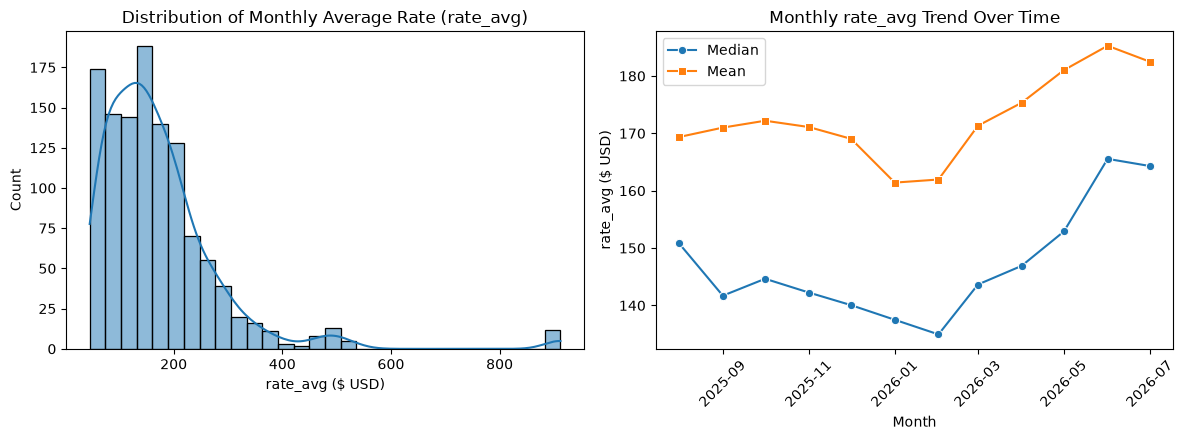

In [ ]:
print("=== Dataset Shapes ===")
for name, d in [("df_merged", df_merged), ("df_6m", df_6m), ("df_3m", df_3m), ("df_1m", df_1m)]:
    print(f"{name}: {d.shape[0]} rows x {d.shape[1]} cols | unique listings: {d['listing_id'].nunique()}")

print("\n=== Target (rate_avg) Summary Across DataFrames ===")
summary_rows = []
for name, d in [("df_merged", df_merged), ("df_6m", df_6m), ("df_3m", df_3m), ("df_1m", df_1m)]:
    s = d["rate_avg"]
    summary_rows.append({
        "dataset": name,
        "n_rows": len(d),
        "n_listings": d["listing_id"].nunique(),
        "mean": round(s.mean(), 2),
        "median": round(s.median(), 2),
        "std": round(s.std(), 2),
        "min": round(s.min(), 2),
        "max": round(s.max(), 2),
    })
display(pd.DataFrame(summary_rows))

print("\n=== Monthly rate_avg Trend ===")
monthly_summary = (
    df_merged.groupby("date")["rate_avg"]
    .agg(count="count", mean="mean", median="median", std="std")
    .reset_index()
)
display(monthly_summary.round(2))

print("\n=== rate_avg by Entire Home Flag ===")
if "room_type_entire_home" in df_merged.columns:
    display(
        df_merged.groupby("room_type_entire_home")["rate_avg"]
        .agg(count="count", mean="mean", median="median", std="std")
        .round(2)
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df_merged["rate_avg"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Monthly Average Rate (rate_avg)")
axes[0].set_xlabel("rate_avg ($ USD)")
axes[0].set_ylabel("Count")

sns.lineplot(data=monthly_summary, x="date", y="median", marker="o", label="Median", ax=axes[1])
sns.lineplot(data=monthly_summary, x="date", y="mean", marker="s", label="Mean", ax=axes[1])
axes[1].set_title("Monthly rate_avg Trend Over Time")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("rate_avg ($ USD)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

=== Candidate Feature Summary (df_merged) ===


,count,mean,std,min,50%,max
bedrooms,1174.0,1.19,0.55,1.0,1.00,5.0
guests,1174.0,2.36,0.88,1.0,2.00,5.0
beds,1174.0,1.59,0.97,1.0,1.00,7.0
baths,1174.0,0.63,0.59,0.0,1.00,3.0
min_nights,1174.0,21.97,12.31,1.0,30.00,35.0
min_nights_avg,1174.0,21.90,12.60,1.0,30.00,60.0
cleaning_fee,1174.0,2070.09,2094.26,0.0,1595.50,7334.0
num_reviews,1174.0,203.37,160.85,2.0,169.00,690.0
rating_overall,1174.0,4.80,0.13,4.4,4.82,5.0
occupancy,1174.0,0.30,0.37,0.0,0.05,1.0


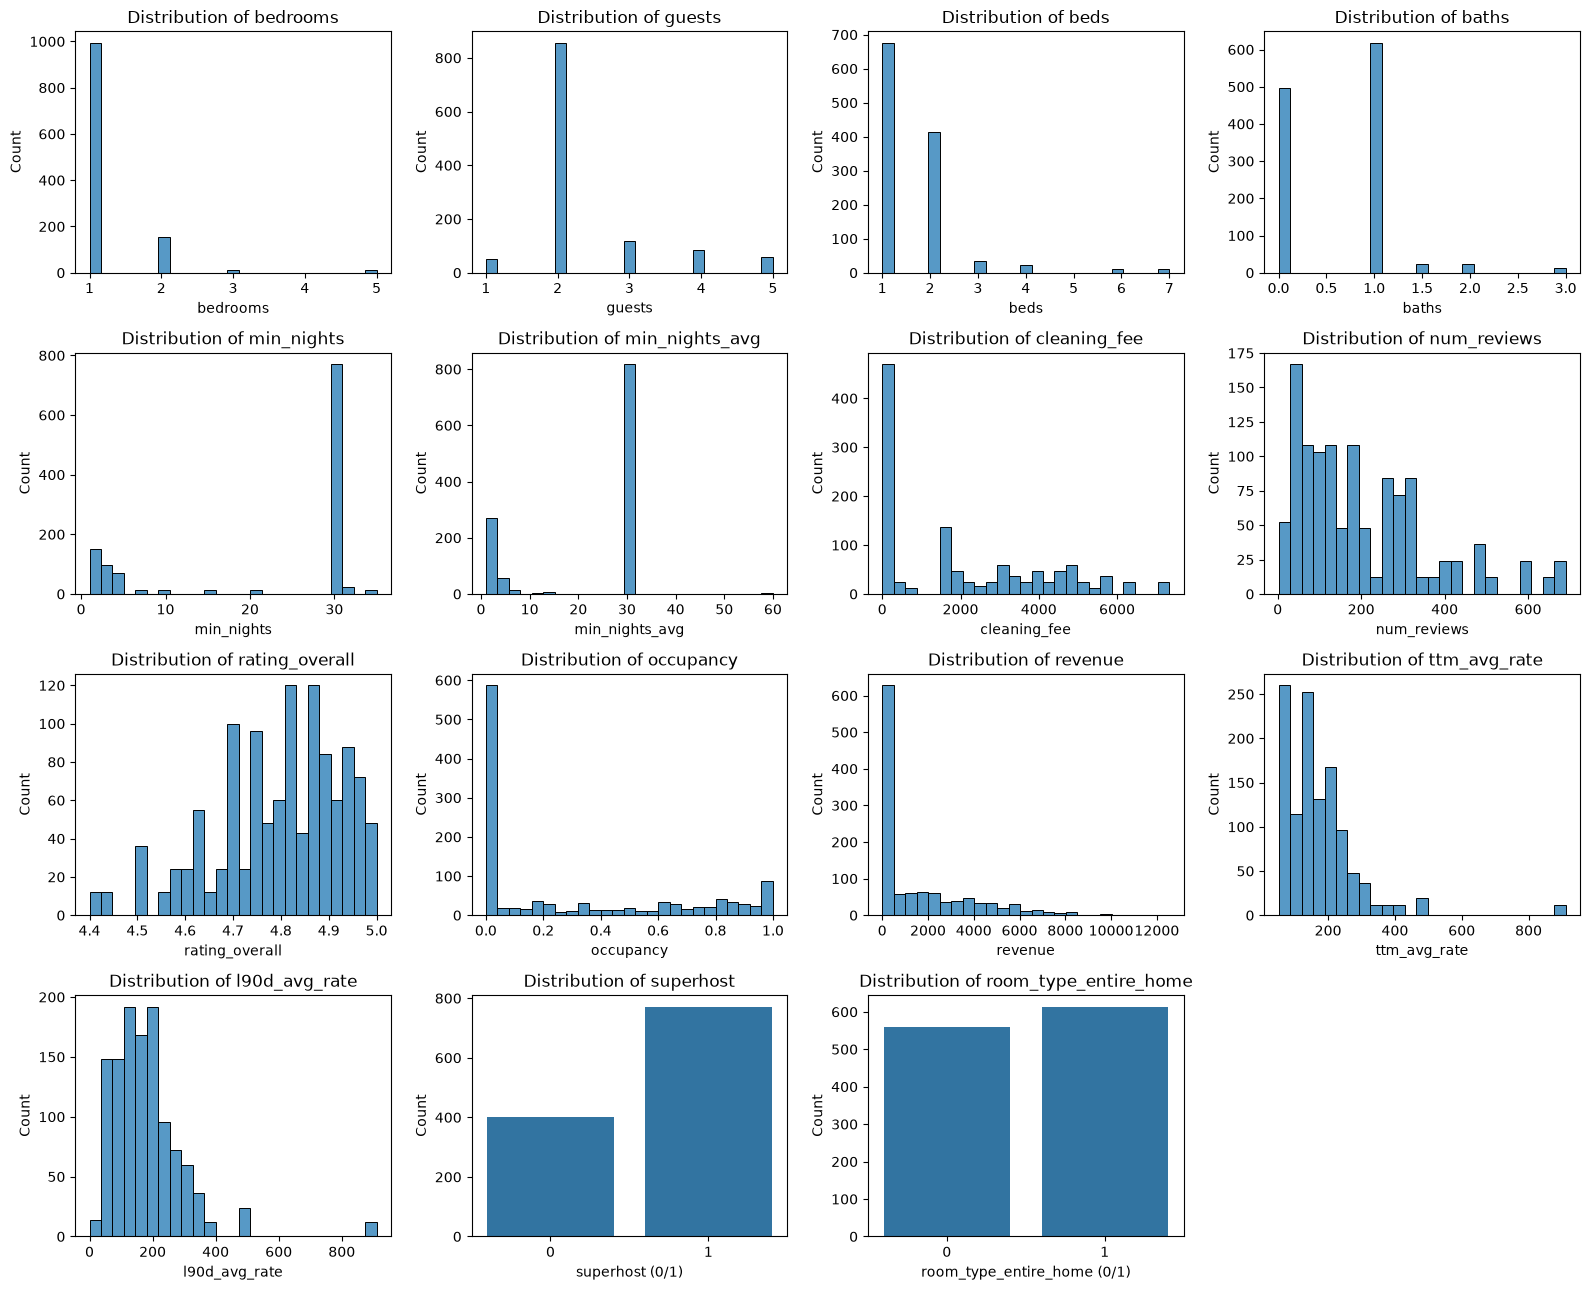

In [18]:
feature_candidates = [
    "bedrooms", "guests", "beds", "baths", "min_nights", "min_nights_avg",
    "cleaning_fee", "num_reviews", "rating_overall", "occupancy", "revenue",
    "ttm_avg_rate", "l90d_avg_rate", "superhost", "room_type_entire_home"
]
present_features = [c for c in feature_candidates if c in df_merged.columns]

print("=== Candidate Feature Summary (df_merged) ===")
display(df_merged[present_features].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

n_cols = 4
n_rows = int(np.ceil(len(present_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.25 * n_rows))
axes_flat = axes.flatten()

for idx, col in enumerate(present_features):
    ax = axes_flat[idx]
    is_binary = set(df_merged[col].dropna().unique()).issubset({0, 1})
    if is_binary:
        sns.countplot(data=df_merged, x=col, ax=ax)
        ax.set_xlabel(f"{col} (0/1)")
    else:
        sns.histplot(df_merged[col], bins=25, kde=False, ax=ax)
        ax.set_xlabel(col)
    ax.set_title(f"Distribution of {col}")
    ax.set_ylabel("Count")

for idx in range(len(present_features), len(axes_flat)):
    axes_flat[idx].axis("off")

plt.tight_layout()
plt.show()

## Build models

In [ ]:
# Train baseline and candidate models.

## Evaluate models

In [ ]:
# Compare models using the chosen evaluation measures.

## Final results

In [ ]:
# Generate the final tables and figures.

## AI usage disclosure

- **AI tool/model:** [Name the tool and model, or state that no generative AI was used.]
- **Used for:** [Briefly identify the tasks.]
- **How we verified the work:** [Briefly identify the checks.]
- **Prompt(s) used:** [Paste the prompts used.]